# Using Gemini API

### Environment: Google Colab + Gemini API (free).

**Exercise 1: Product/Service Review Sentiment Analysis**

- Create a list of approximately 15–20 actual reviews/ratings.

- Use Pydantic to instruct the model to return each line including: sentiment (positive/negative/neutral), score (from -1.0 to 1.0), and key_points.

- Call the API to process the list of reviews, save the results to a table/DataFrame, and calculate the percentage of each sentiment type.



### Create API Keys

**Method 1:** Click on the Key icon (🔑) in the left-hand sidebar of Google Colab.

- Add a new secret with the Name: GOOGLE_API_KEY.

- Paste your Gemini API key into the Value field.

- Toggle on Notebook access for this secret.

**Method 2 (recommended):**

- Go to: [Google AI Studio](https://aistudio.google.com/app/api-keys?utm_source=colab.research.google.com&utm_medium=referral&utm_campaign=colab-integration&utm_content=owned-promo)

- Log in with your Google Account

- At the left of the main screen, select **API Keys**

- When you are in the API Keys section, at the top right, select **Create API Keys**

- Simply follow its instruction and you will have your first API Key

- Once done, you can proceed with the code below

In [2]:
import pandas as pd
from pydantic import BaseModel, Field
from typing import List
from google import genai
from google.genai import types
from google.colab import userdata
import getpass

# Configure Gemini Client
# We attempt to retrieve the key from Colab Secrets. If not found, we ask for it securely.
try:
    api_key = userdata.get('GOOGLE_API_KEY')
except Exception:
    print("GOOGLE_API_KEY not found in Colab Secrets.")
    api_key = getpass.getpass("Please enter your Gemini API Key: ")
    # If it works, print accept
    print("API Key accepted.")

client = genai.Client(api_key=api_key)

GOOGLE_API_KEY not found in Colab Secrets.
Please enter your Gemini API Key: ··········
API Key accepted.


In [3]:
# Define the schema using Pydantic for structured outputs
class ReviewAnalysis(BaseModel):
    sentiment: str = Field(description="Sentiment classification: positive, negative, or neutral")
    score: float = Field(description="Sentiment score ranging from -1.0 (extremely negative) to 1.0 (extremely positive)")
    key_points: List[str] = Field(description="Key points summarized from the review")

class BatchReviewAnalysis(BaseModel):
    analyses: List[ReviewAnalysis] = Field(description="List of analyzed reviews corresponding to the inputs")

In [8]:
import time
from google.genai.errors import APIError

# Create list of 15-20 reviews
reviews = [
    "Absolutely love this product! It has changed my daily routine for the better and works flawlessly.",
    "Terrible experience. The build quality feels cheap and it stopped working after just three days.",
    "It is okay, does what it is supposed to do but nothing extraordinary. Standard performance.",
    "I was skeptical at first, but this exceeded all my expectations. Highly recommended!",
    "The user interface is extremely frustrating and hard to navigate. I want a refund.",
    "Customer support was helpful, but the product itself is mediocre and slow.",
    "Fantastic build quality, premium packaging, and incredibly fast delivery.",
    "Avoid this at all costs. It arrived damaged and the company refused to replace it.",
    "An average product with a slightly overpriced tag. It's decent if bought on sale.",
    "Best purchase I've made this year. Excellent value for money.",
    "The battery life is abysmal. It barely lasts two hours on a full charge.",
    "It's fine, nothing special. It works as advertised but has a generic design.",
    "This tool saves me so much time every single day. Brilliant design.",
    "Extremely disappointed. It does not look or function like the advertisements at all.",
    "Pretty standard item. It is neither amazing nor terrible. Just average.",
    "Wow! The sound quality is crystal clear and the noise cancellation is superb."
]

# Fallback configuration to handle service availability issues dynamically
primary_model = 'gemini-3.5-flash-lite'
fallback_model = 'gemini-3.8-flash'

try:
    print(f"Attempting to process with primary model: {primary_model}...")
    response = client.models.generate_content(
        model=primary_model,
        contents=["Analyze the sentiment of the following list of reviews sequentially, returning one analysis object per review in the exact same order:", f"{reviews}"],
        config=types.GenerateContentConfig(
            response_mime_type="application/json",
            response_schema=BatchReviewAnalysis,
            temperature=0.0
        ),
    )
    print("Successfully analyzed using primary model!")
except Exception as e:
    print(f"Primary model failed with error: {e}. Falling back to {fallback_model}...")
    time.sleep(2) # Brief pause before retrying
    response = client.models.generate_content(
        model=fallback_model,
        contents=["Analyze the sentiment of the following list of reviews sequentially, returning one analysis object per review in the exact same order:", f"{reviews}"],
        config=types.GenerateContentConfig(
            response_mime_type="application/json",
            response_schema=BatchReviewAnalysis,
            temperature=0.0
        ),
    )
    print("Successfully analyzed using fallback model!")

Attempting to process with primary model: gemini-3.5-flash-lite...
Successfully analyzed using primary model!


In [9]:
# Load the result into a pandas DataFrame
import json

result_data = json.loads(response.text)
analyses_list = result_data["analyses"]

# Match the original reviews back to the predictions
df = pd.DataFrame(analyses_list)
df.insert(0, "review", reviews)

# Display the DataFrame
display(df)

,review,sentiment,score,key_points
0,Absolutely love this product! It has changed m...,positive,0.95,"[Loves the product, Improved daily routine, Wo..."
1,Terrible experience. The build quality feels c...,negative,-0.95,"[Terrible experience, Cheap build quality, Sto..."
2,"It is okay, does what it is supposed to do but...",neutral,0.00,"[Does what it is supposed to do, Nothing extra..."
3,"I was skeptical at first, but this exceeded al...",positive,0.90,"[Exceeded expectations, Highly recommended, Ov..."
4,The user interface is extremely frustrating an...,negative,-0.90,"[Frustrating user interface, Hard to navigate,..."
5,"Customer support was helpful, but the product ...",neutral,-0.20,"[Helpful customer support, Mediocre product, S..."
6,"Fantastic build quality, premium packaging, an...",positive,0.95,"[Fantastic build quality, Premium packaging, I..."
7,Avoid this at all costs. It arrived damaged an...,negative,-0.95,"[Arrived damaged, Company refused to replace i..."
8,An average product with a slightly overpriced ...,neutral,-0.10,"[Average product, Slightly overpriced, Decent ..."
9,Best purchase I've made this year. Excellent v...,positive,0.95,"[Best purchase of the year, Excellent value fo..."


In [10]:
# Calculate and display the percentage of each sentiment type
sentiment_counts = df['sentiment'].str.lower().value_counts(normalize=True) * 100
print("--- Sentiment Distribution Percentage ---")
for sentiment, percentage in sentiment_counts.items():
    print(f"{sentiment.capitalize()}: {percentage:.2f}%")

--- Sentiment Distribution Percentage ---
Positive: 37.50%
Negative: 31.25%
Neutral: 31.25%


**Exercise 2: Text Extraction from Images/Documents (Basic OCR)**

- Select a photo of a lecture slide, book/document page, invoice, or screenshot containing text.

- Feed each image into the model to extract the entire text while maintaining the correct reading order; for invoice/form images, request a summary of the key information.

Please upload a photo of a lecture slide, book page, invoice, or screenshot containing text:


Saving Specialized AI Models.JPG to Specialized AI Models.JPG

Successfully uploaded: Specialized AI Models.JPG


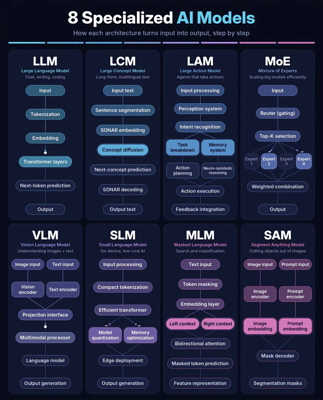

In [11]:
from google.colab import files
import os
from PIL import Image

print("Please upload a photo of a lecture slide, book page, invoice, or screenshot containing text:")
uploaded = files.upload()

# Get the first uploaded file path
if uploaded:
    image_path = list(uploaded.keys())[0]
    print(f"\nSuccessfully uploaded: {image_path}")
    # Display a preview of the uploaded image
    img = Image.open(image_path)
    img.thumbnail((400, 400))
    display(img)
else:
    print("No file uploaded.")

In [12]:
if 'image_path' in locals() and os.path.exists(image_path):
    # Load image for the API
    image_input = Image.open(image_path)

    prompt = (
        "Perform OCR on this image. Extract the entire text while maintaining "
        "the correct reading order. If this is an invoice or a form, "
        "provide a concise summary of the key information at the end."
    )

    print("Processing image with Gemini...")
    try:
        response = client.models.generate_content(
            model='gemini-3.5-flash-lite',
            contents=[image_input, prompt]
        )
        print("\n--- Extracted Text and Analysis ---\n")
        print(response.text)
    except Exception as e:
        print(f"An error occurred during API execution: {e}")
else:
    print("Please upload an image in the previous step first.")

Processing image with Gemini...

--- Extracted Text and Analysis ---

8 Specialized AI Models
How each architecture turns input into output, step by step

LLM
Large Language Model
Chat, writing, coding
Input
Tokenization
Embedding
Transformer layers
Next-token prediction
Output

LCM
Large Concept Model
Long-form, multilingual text
Input text
Sentence segmentation
SONAR embedding
Concept diffusion
Next-concept prediction
SONAR decoding
Output text

LAM
Large Action Model
Agents that take actions
Input processing
Perception system
Intent recognition
Task breakdown
Memory system
Action planning
Neuro-symbolic reasoning
Action execution
Feedback integration

MoE
Mixture of Experts
Scaling big models efficiently
Input
Router (gating)
Top-K selection
Expert 1
Expert 2
Expert 3
Expert 4
Weighted combination
Output

VLM
Vision Language Model
Understanding images + text
Image input
Text input
Vision encoder
Text encoder
Projection interface
Multimodal processor
Language model
Output generation


## Recap of your Gemini API Journey

We have successfully implemented two core, powerful workflows using the new Google GenAI SDK:

**1. Structured Outputs (Exercise 1):** You defined a schema using Pydantic (ReviewAnalysis), requested JSON output conforming precisely to that schema, and analyzed batch feedback using gemini-3.5-flash-lite.

**2. Multimodal Analysis & OCR (Exercise 2):** You uploaded a diagram (Specialized AI Models.JPG) using colab.upload and processed it with Gemini to extract text flawlessly while preserving structure.


#### What Kind of Systems Can You Build?
Because the Gemini model handles text, code, images, audio, and video with a massive context window, you can use these exact patterns to design production-ready applications:

**① Intelligent Document Processing (IDP) / Invoice Automation**

- **How it works:** Combine the file uploading and structured output patterns.

- **What you can build:** A system that reads invoices, bills, receipts, or shipping manifests, and extracts key data fields (e.g., total_amount, vendor_name, line_items) directly into a clean SQL database or Pandas DataFrame without manual entry.

**② Automated Customer Feedback & Sentiment Hub**

- **How it works:** Use batch structured reviews processing on an automated schedule.
What you can build: A pipeline that imports product reviews, customer support emails, or social media mentions daily, analyzes sentiment + key grievances using structured JSON, and feeds a real-time dashboard tracking brand health.

**③ AI-Powered Meeting Assistant
How it works: Leverage Gemini's large context window to process multi-format inputs.**

- **What you can build:** Feed an entire audio recording or transcript of a meeting, extract action items using a structured schema (TaskName, Assignee, Deadline), and automatically send updates to project management tools (like Jira, Trello, or Notion).

**④ Visual Search and Recommendation Engine**

- **How it works:** Multimodal generation.

- **What you can build:** An e-commerce helper where users upload a photo of an item they like (e.g., a piece of furniture or clothing) and the model generates search terms, identifies the style, and suggests matching items from an inventory list.